# Controlled overlap experiment: SVM, KNN, RF and LR

Saved actual evaluations on independent synthetic data. RF/LR were retained after examining benchmark results; this is exploratory classifier selection. All GaussianNB results remain in progress.md. Each curve uses 20 independent seeds; distances share base draws within a seed. Run all cells to reproduce plots and statistical summaries from embedded records. Original simulation execution code is retained in metadata.original_execution_code; the shared classifier_expansion function implements and resumes RF/LR/GaussianNB fits.

In [1]:
from pathlib import Path
import sys, json, hashlib, time, platform, importlib.metadata
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import matthews_corrcoef, f1_score, precision_score, recall_score
from threadpoolctl import threadpool_limits
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/'binary_oversampling.py').exists():ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from binary_oversampling import sampler, classifier
OUT=ROOT/'paper_material';NBPATH=OUT/'CASB_Overlap_Experiment.ipynb'
thread_guard=threadpool_limits(limits=1)
METHODS=['original','smote','bsmote','ros','adasyn','casb','casb_relaxed','casb_edited','casb_ros']
CLASSIFIERS=['svm','knn'];RATIOS=[.5,.75,1.]
DISTANCES=[float(x) for x in np.arange(5,-.01,-.5)]
SEEDS=list(range(20260,20280))
CONFIG=dict(methods=METHODS,classifiers=CLASSIFIERS,ratios=RATIOS,distances=DISTANCES,seeds=SEEDS,
    train_counts=[400,40],test_counts=[1000,100],class_covariances='identity 2x2 for both classes',
    centers='majority (0,0); minority (d,0)',label_noise=0,validation_fraction=.25,
    selection='(minority F1 + G-mean)/2; ties prefer smaller ratio',
    pairing='same independent training/test base normal draws across distances within each seed; same data across methods',
    implementation_sha256=hashlib.sha256((ROOT/'binary_oversampling.py').read_bytes()).hexdigest(),
    versions={k:importlib.metadata.version(k) for k in ['numpy','scipy','scikit-learn','imbalanced-learn']},
    python=platform.python_version())
SIGNATURE=hashlib.sha256(json.dumps(CONFIG,sort_keys=True).encode()).hexdigest()
def metric_values(y,p):
    tn,fp,fn,tp=np.bincount(2*y.astype(int)+p.astype(int),minlength=4).astype(float)
    C=np.array([[tn,fp],[fn,tp]])
    row=C.sum(1);col=C.sum(0);diag=np.diag(C)
    iam=np.mean((diag-np.maximum(row-diag,col-diag))/np.maximum(row,col))
    den=np.sqrt((tp+fp)*(tp+fn)*(tn+fp)*(tn+fn))
    return dict(gmean=float(np.sqrt(tp/max(1,tp+fn)*tn/max(1,tn+fp))),
       f1=float(2*tp/max(1,2*tp+fp+fn)),precision=float(tp/max(1,tp+fp)),recall=float(tp/max(1,tp+fn)),
       mcc=float((tp*tn-fp*fn)/den) if den else 0.,iam=float(iam),confusion=[int(tn),int(fp),int(fn),int(tp)])
# Meaningful metric checks, including boundary cases for IAM.
yy=np.array([0,0,1,1]);assert metric_values(yy,yy)['iam']==1
assert metric_values(yy,1-yy)['iam']==-1
assert metric_values(yy,np.array([0,1,0,1]))['iam']==0
yy=np.r_[np.zeros(10,int),np.ones(2,int)];assert np.isclose(metric_values(yy,np.zeros(12,int))['iam'],-1/6)
rng=np.random.default_rng(19);yy=rng.integers(0,2,100);pp=rng.integers(0,2,100);test=metric_values(yy,pp)
assert np.isclose(test['mcc'],matthews_corrcoef(yy,pp))
assert np.isclose(test['f1'],f1_score(yy,pp)) and np.isclose(test['precision'],precision_score(yy,pp)) and np.isclose(test['recall'],recall_score(yy,pp))
def fit_score(X,y,T,yt,clf,seed):
    model=classifier(clf,seed)
    if clf=='knn':model.set_params(n_neighbors=min(7,len(y)))
    model.fit(X,y);return metric_values(yt,model.predict(T))
def resampled(X,y,method,seed,ratio):
    s=sampler(method,y,seed,ratio)
    return (X.copy(),y.copy()) if s is None else s.fit_resample(X,y)
print('Frozen configuration:',json.dumps(CONFIG,indent=2))
print('IAM formula checked against uploaded paper page 9; confusion-matrix checks passed.')


Frozen configuration: {
  "methods": [
    "original",
    "smote",
    "bsmote",
    "ros",
    "adasyn",
    "casb",
    "casb_relaxed",
    "casb_edited",
    "casb_ros"
  ],
  "classifiers": [
    "svm",
    "knn"
  ],
  "ratios": [
    0.5,
    0.75,
    1.0
  ],
  "distances": [
    5.0,
    4.5,
    4.0,
    3.5,
    3.0,
    2.5,
    2.0,
    1.5,
    1.0,
    0.5,
    0.0
  ],
  "seeds": [
    20260,
    20261,
    20262,
    20263,
    20264,
    20265,
    20266,
    20267,
    20268,
    20269,
    20270,
    20271,
    20272,
    20273,
    20274,
    20275,
    20276,
    20277,
    20278,
    20279
  ],
  "train_counts": [
    400,
    40
  ],
  "test_counts": [
    1000,
    100
  ],
  "class_covariances": "identity 2x2 for both classes",
  "centers": "majority (0,0); minority (d,0)",
  "label_noise": 0,
  "validation_fraction": 0.25,
  "selection": "(minority F1 + G-mean)/2; ties prefer smaller ratio",
  "pairing": "same independent training/test base normal draws acro

In [2]:
saved=json.loads(NBPATH.read_text(encoding='utf8'))['metadata']
records=list(saved['overlap_experiment']['records'])+list(saved['classifier_extension']['records'])
provenance=saved['overlap_experiment']['data_provenance']
CLASSIFIERS=['svm','knn','rf','lr']
assert len(records)==7920
assert len({(r['seed'],r['distance'],r['method'],r['classifier']) for r in records})==7920
print('Loaded 7920 actual evaluations; separate original and extension provenance preserved.')


Loaded 7920 actual evaluations; separate original and extension provenance preserved.


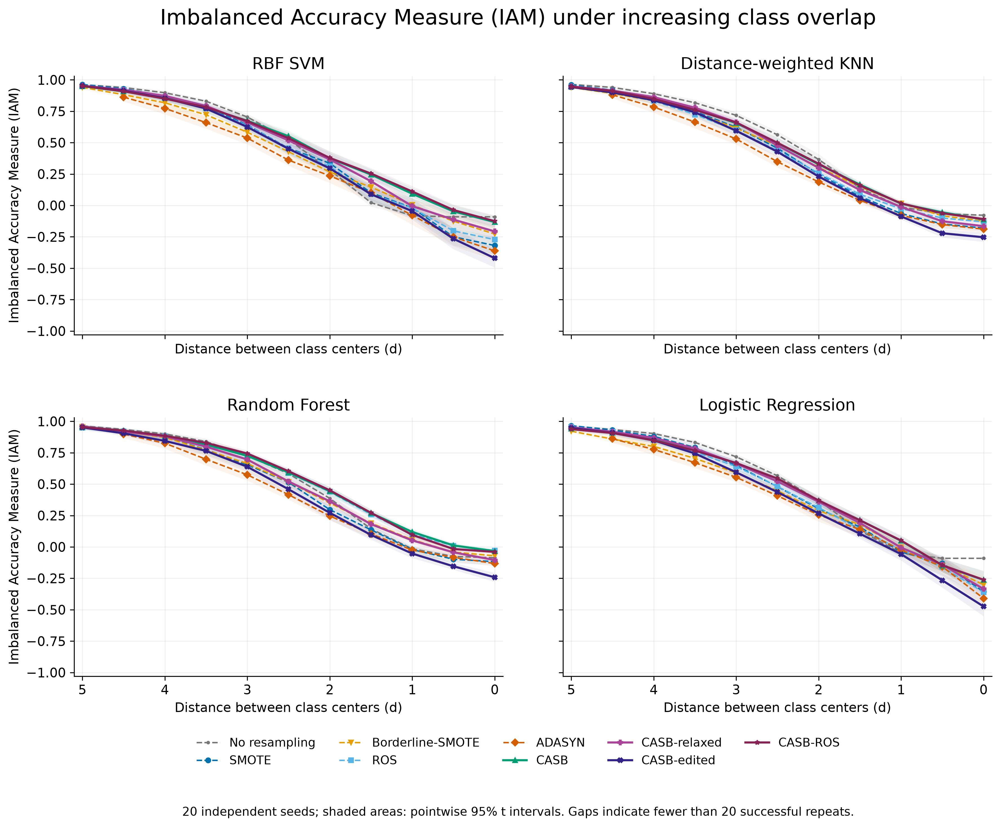

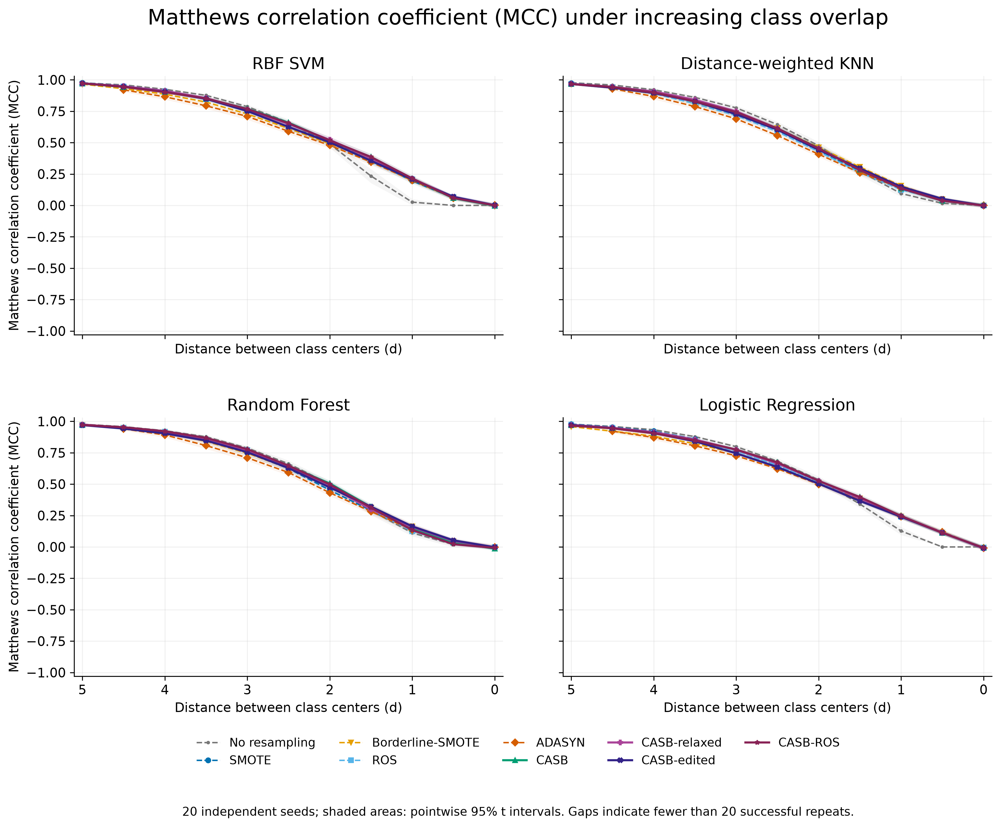

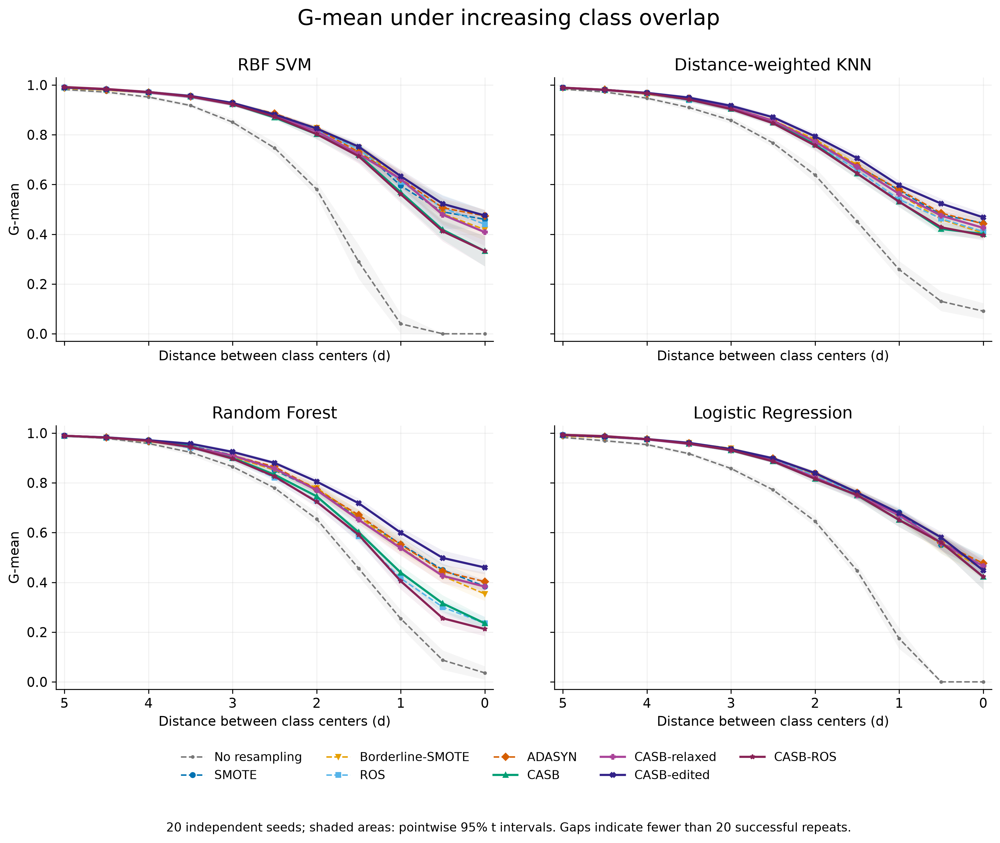

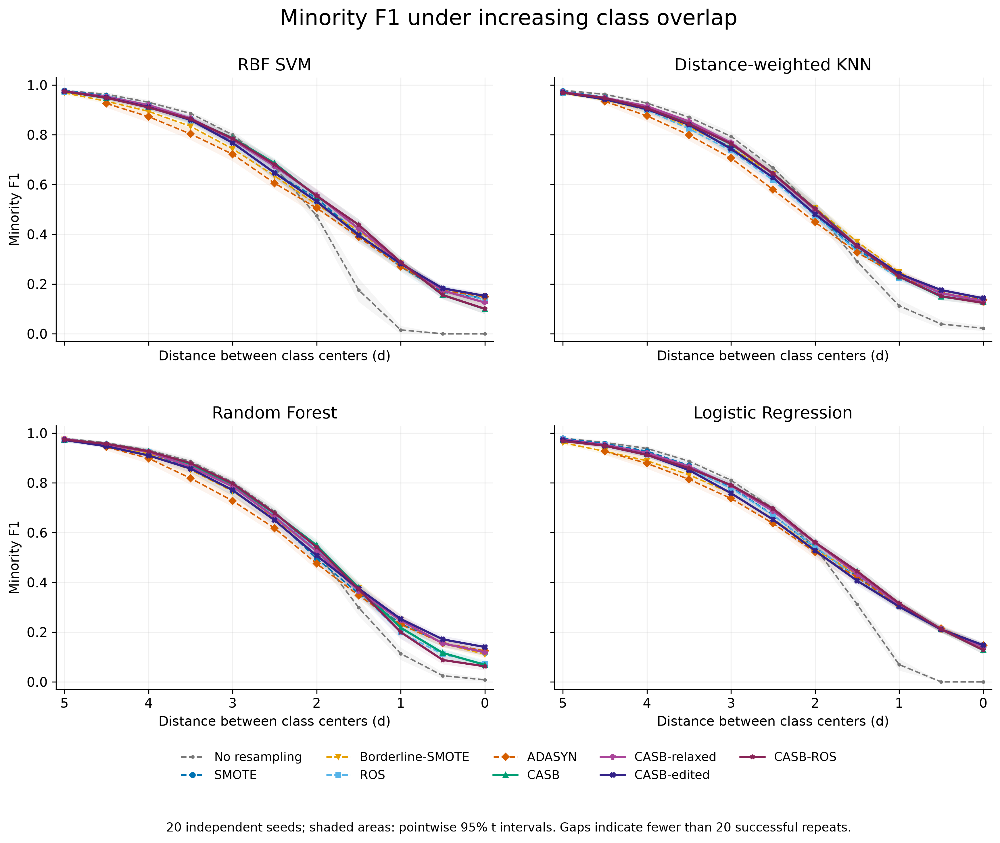

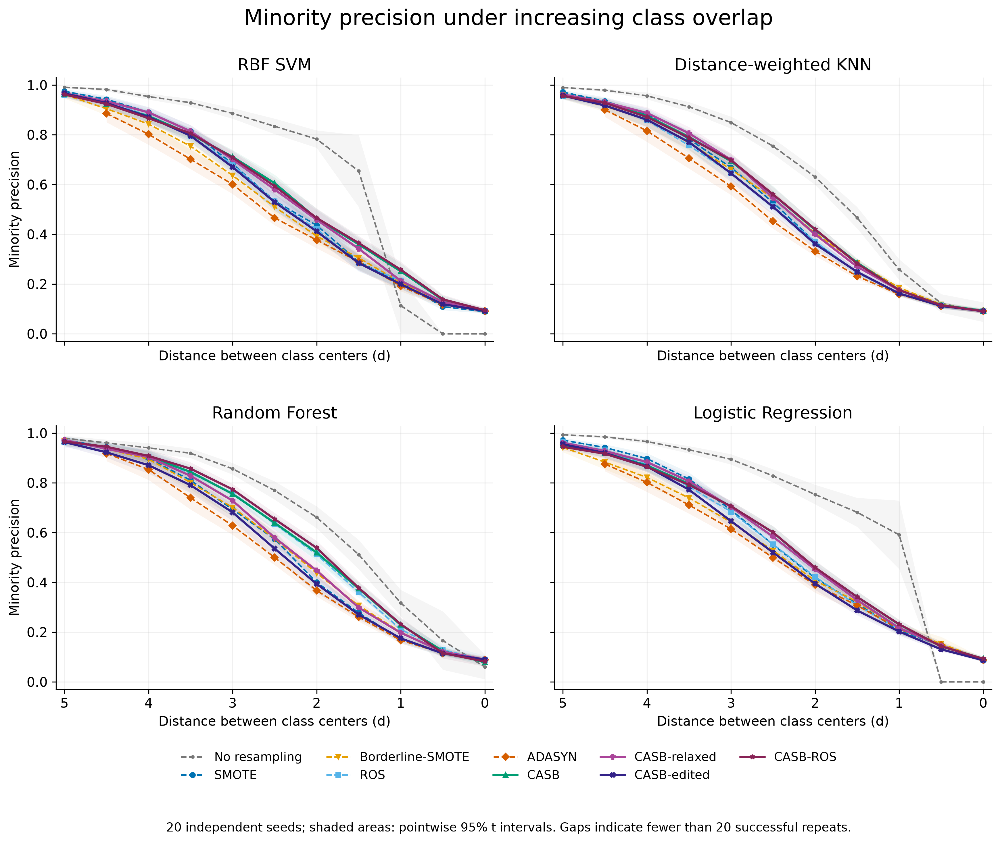

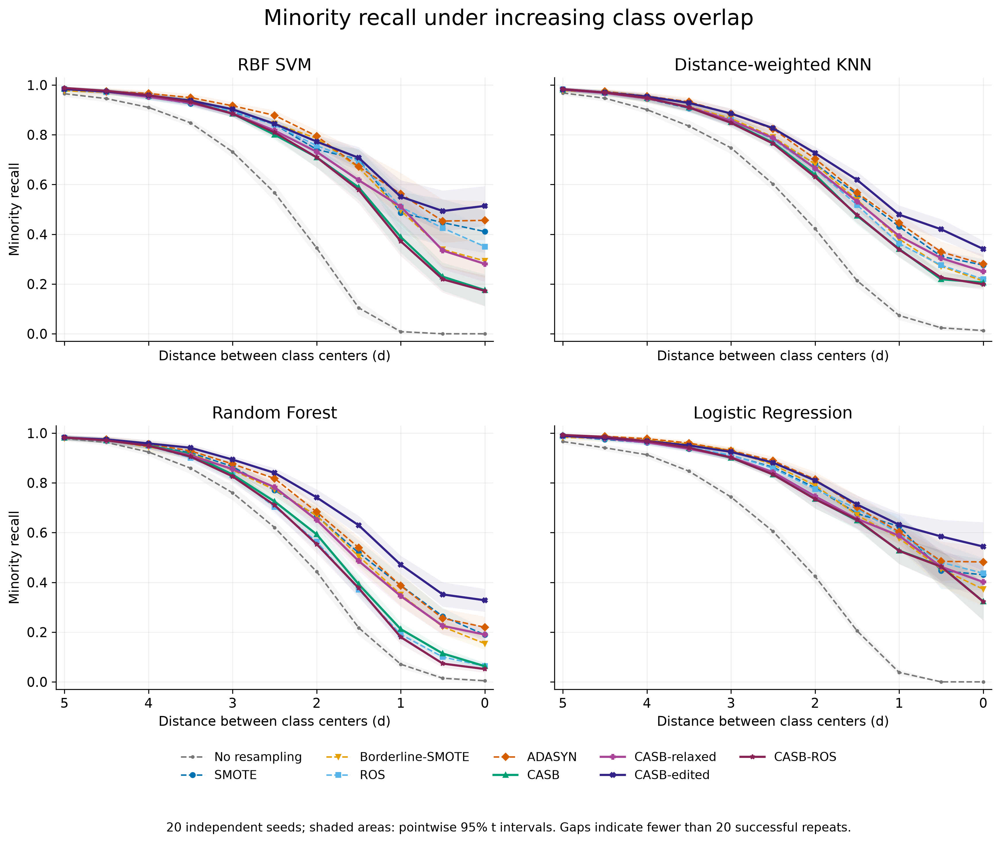

distance                 0.0  0.5  1.0  1.5  2.0  2.5  3.0  3.5  4.0  4.5  5.0
classifier method                                                             
svm        original       20   20   20   20   20   20   20   20   20   20   20
           smote          20   20   20   20   20   20   20   20   20   20   20
           bsmote         20   20   20   20   20   20   20   20   20   20   20
           ros            20   20   20   20   20   20   20   20   20   20   20
           adasyn         20   20   20   20   20   20   20   20   20   20   18
           casb           20   20   20   20   20   20   20   20   20   20   20
           casb_relaxed   20   20   20   20   20   20   20   20   20   20   20
           casb_edited    20   20   20   20   20   20   20   20   20   20   20
           casb_ros       20   20   20   20   20   20   20   20   20   20   20
knn        original       20   20   20   20   20   20   20   20   20   20   20
           smote          20   20   20   20   20   20   20   20   20   20   20
           bsmote         20   20   20   20   20   20   20   20   20   20   20
           ros            20   20   20   20   20   20   20   20   20   20   20
           adasyn         20   20   20   20   20   20   20   20   20   20   18
           casb           20   20   20   20   20   20   20   20   20   20   20
           casb_relaxed   20   20   20   20   20   20   20   20   20   20   20
           casb_edited    20   20   20   20   20   20   20   20   20   20   20
           casb_ros       20   20   20   20   20   20   20   20   20   20   20
rf         original       20   20   20   20   20   20   20   20   20   20   20
           smote          20   20   20   20   20   20   20   20   20   20   20
           bsmote         20   20   20   20   20   20   20   20   20   20   20
           ros            20   20   20   20   20   20   20   20   20   20   20
           adasyn         20   20   20   20   20   20   20   20   20   20   18
           casb           20   20   20   20   20   20   20   20   20   20   20
           casb_relaxed   20   20   20   20   20   20   20   20   20   20   20
           casb_edited    20   20   20   20   20   20   20   20   20   20   20
           casb_ros       20   20   20   20   20   20   20   20   20   20   20
lr         original       20   20   20   20   20   20   20   20   20   20   20
           smote          20   20   20   20   20   20   20   20   20   20   20
           bsmote         20   20   20   20   20   20   20   20   20   20   20
           ros            20   20   20   20   20   20   20   20   20   20   20
           adasyn         20   20   20   20   20   20   20   20   20   20   18
           casb           20   20   20   20   20   20   20   20   20   20   20
           casb_relaxed   20   20   20   20   20   20   20   20   20   20   20
           casb_edited    20   20   20   20   20   20   20   20   20   20   20
           casb_ros       20   20   20   20   20   20   20   20   20   20   20

,seed,distance,method,classifier,error
1394,20267,5.0,adasyn,svm,ValueError: No valid inner-validation ratio; s...
1395,20267,5.0,adasyn,knn,ValueError: No valid inner-validation ratio; s...
3176,20276,5.0,adasyn,svm,ValueError: No valid inner-validation ratio; s...
3177,20276,5.0,adasyn,knn,ValueError: No valid inner-validation ratio; s...
5332,20267,5.0,adasyn,rf,RuntimeError: Not any neigbours belong to the ...
5341,20267,5.0,adasyn,lr,RuntimeError: Not any neigbours belong to the ...
7114,20276,5.0,adasyn,rf,RuntimeError: Not any neigbours belong to the ...
7123,20276,5.0,adasyn,lr,RuntimeError: Not any neigbours belong to the ...


iam                       mcc            \
                                mean       std count      mean       std   
classifier method distance                                                 
knn        adasyn 0.0      -0.189082  0.066379    20  0.000239  0.038373   
                  0.5      -0.152219  0.066651    20  0.042655  0.038581   
                  1.0      -0.079043  0.053453    20  0.137370  0.035819   
                  1.5       0.040869  0.056666    20  0.260247  0.039551   
                  2.0       0.187232  0.067398    20  0.407761  0.049197   
...                              ...       ...   ...       ...       ...   
svm        smote  3.0       0.640192  0.078993    20  0.754057  0.037725   
                  3.5       0.790023  0.053342    20  0.853589  0.027723   
                  4.0       0.871014  0.042695    20  0.912267  0.022470   
                  4.5       0.928953  0.029141    20  0.952301  0.016662   
                  5.0       0.962285  0.017931    20  0.976076  0.010348   

                                     gmean                        f1  \
                           count      mean       std count      mean   
classifier method distance                                             
knn        adasyn 0.0         20  0.442147  0.056328    20  0.136109   
                  0.5         20  0.485256  0.055275    20  0.164645   
                  1.0         20  0.579705  0.040284    20  0.232929   
                  1.5         20  0.674580  0.041969    20  0.326681   
                  2.0         20  0.774325  0.038144    20  0.448709   
...                          ...       ...       ...   ...       ...   
svm        smote  3.0         20  0.923420  0.018809    20  0.770622   
                  3.5         20  0.951230  0.013753    20  0.865180   
                  4.0         20  0.969955  0.011923    20  0.919412   
                  4.5         20  0.982596  0.010283    20  0.956337   
                  5.0         20  0.989638  0.007193    20  0.978133   

                                           precision                  recall  \
                                 std count      mean       std count    mean   
classifier method distance                                                     
knn        adasyn 0.0       0.028562    20  0.090968  0.018335    20  0.2805   
                  0.5       0.029517    20  0.111231  0.019765    20  0.3290   
                  1.0       0.026092    20  0.158807  0.018952    20  0.4455   
                  1.5       0.031193    20  0.231419  0.025229    20  0.5665   
                  2.0       0.042624    20  0.331732  0.040646    20  0.7035   
...                              ...   ...       ...       ...   ...     ...   
svm        smote  3.0       0.037662    20  0.682992  0.065266    20  0.8915   
                  3.5       0.026027    20  0.815027  0.051604    20  0.9250   
                  4.0       0.020933    20  0.890508  0.045774    20  0.9525   
                  4.5       0.015299    20  0.942558  0.030543    20  0.9715   
                  5.0       0.009474    20  0.974740  0.020106    20  0.9820   

                                            
                                 std count  
classifier method distance                  
knn        adasyn 0.0       0.082556    20  
                  0.5       0.089319    20  
                  1.0       0.073733    20  
                  1.5       0.079689    20  
                  2.0       0.074075    20  
...                              ...   ...  
svm        smote  3.0       0.041457    20  
                  3.5       0.029110    20  
                  4.0       0.025726    20  
                  4.5       0.021343    20  
                  5.0       0.015079    20  

[396 rows x 18 columns]

Attempted outer evaluations: 7920 successful: 7912 failed: 8
Failures by distance and method:


method,adasyn
distance,
5.0,8


,classifier,metric,distance,best_family,best_baseline,delta
0,svm,iam,4.5,casb_relaxed,smote,-0.008079
1,svm,iam,4.0,casb_relaxed,smote,0.001342
2,svm,iam,3.5,casb_relaxed,smote,0.002345
3,svm,iam,3.0,casb,smote,0.034382
4,svm,iam,2.5,casb,smote,0.095078
...,...,...,...,...,...,...
235,lr,recall,2.0,casb_edited,adasyn,-0.004500
236,lr,recall,1.5,casb_edited,adasyn,0.011500
237,lr,recall,1.0,casb_edited,smote,0.006500
238,lr,recall,0.5,casb_edited,adasyn,0.100000


Six curve figures and six-page PDF saved.


In [3]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy.stats import t as student_t
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'pdf.fonttype':42,'ps.fonttype':42,'svg.fonttype':'none'})
frame=pd.DataFrame(records)
if 'error' not in frame:frame['error']=None
valid=frame[frame.error.isna()].copy();failures=frame[frame.error.notna()]
METRICS=['iam','mcc','gmean','f1','precision','recall']
assert np.isfinite(valid[METRICS]).all().all()
for _,r in valid.iterrows():
    tn,fp,fn,tp=r.confusion;assert tn+fp==1000 and fn+tp==100
    assert -1<=r.iam<=1 and -1<=r.mcc<=1 and 0<=r.gmean<=1
    if r.validation:
        choices=[q for q in r.validation if 'objective' in q]
        assert r.ratio==max(choices,key=lambda t:(t['objective'],-t['ratio']))['ratio']
aggregate=valid.groupby(['classifier','method','distance'])[METRICS].agg(['mean','std','count'])
names={'original':'No resampling','smote':'SMOTE','bsmote':'Borderline-SMOTE','ros':'ROS','adasyn':'ADASYN','casb':'CASB','casb_relaxed':'CASB-relaxed','casb_edited':'CASB-edited','casb_ros':'CASB-ROS'}
colors=['#777777','#0072B2','#E69F00','#56B4E9','#D55E00','#009E73','#AA4499','#332288','#882255']
markers=['.','o','v','s','D','^','P','X','*']
titles={'iam':'Imbalanced Accuracy Measure (IAM)','mcc':'Matthews correlation coefficient (MCC)','gmean':'G-mean','f1':'Minority F1','precision':'Minority precision','recall':'Minority recall'}
figpaths=[]
coverage=valid.groupby(['classifier','method','distance']).size().unstack('distance').reindex(pd.MultiIndex.from_product([CLASSIFIERS,METHODS],names=['classifier','method'])).fillna(0).astype(int)
for idx,metric in enumerate(METRICS,15):
    fig,axs=plt.subplots(2,2,figsize=(14,10),sharex=True,sharey=True)
    for ax,clf in zip(axs.flat,CLASSIFIERS):
        for method,color,marker in zip(METHODS,colors,markers):
            means=[];ci=[]
            for d in DISTANCES:
                key=(clf,method,d)
                if key not in aggregate.index or aggregate.loc[key,(metric,'count')]!=20:means.append(np.nan);ci.append(np.nan);continue
                means.append(aggregate.loc[key,(metric,'mean')]);ci.append(student_t.ppf(.975,19)*aggregate.loc[key,(metric,'std')]/np.sqrt(20))
            means=np.asarray(means);ci=np.asarray(ci)
            ax.plot(DISTANCES,means,color=color,marker=marker,markersize=4,linewidth=1.8 if method.startswith('casb') else 1.25,linestyle='-' if method.startswith('casb') else '--',label=names[method])
            ax.fill_between(DISTANCES,means-ci,means+ci,color=color,alpha=.07,linewidth=0)
        ax.set_title({'svm':'RBF SVM','knn':'Distance-weighted KNN','rf':'Random Forest','lr':'Logistic Regression'}[clf],fontsize=14)
        ax.set_xlim(5.1,-.1);ax.set_xticks(np.arange(5,-.01,-1));ax.set_xlabel('Distance between class centers (d)')
        ax.set_ylim((-1.03,1.03) if metric in ['iam','mcc'] else (-.03,1.03));ax.grid(alpha=.18);ax.spines[['top','right']].set_visible(False)
    axs[0,0].set_ylabel(titles[metric]);axs[1,0].set_ylabel(titles[metric]);fig.suptitle(titles[metric]+' under increasing class overlap',fontsize=18,y=.98)
    handles,labels=axs[0,0].get_legend_handles_labels();fig.legend(handles,labels,loc='lower center',ncol=5,bbox_to_anchor=(.5,.07),frameon=False,fontsize=10)
    fig.text(.5,.025,'20 independent seeds; shaded areas: pointwise 95% t intervals. Gaps indicate fewer than 20 successful repeats.',ha='center',fontsize=10)
    fig.subplots_adjust(top=.90,bottom=.19,wspace=.14,hspace=.32)
    stem=f'{idx:02d}_overlap_{metric}'
    for ext in ['png','pdf','svg']:fig.savefig(OUT/(stem+'.'+ext),dpi=300,bbox_inches='tight',facecolor='white')
    plt.close(fig);figpaths.append(stem)
    display(Image(filename=str(OUT/(stem+'.png')),width=1100))
display(coverage);display(failures[['seed','distance','method','classifier','error']])
display(aggregate)
print('Attempted outer evaluations:',len(frame),'successful:',len(valid),'failed:',len(failures))
print('Failures by distance and method:')
display(failures.groupby(['distance','method']).size().unstack(fill_value=0))
# Descriptive pairwise mean differences only; no oracle or independence claims across d.
summary=[]
for clf in CLASSIFIERS:
    for metric in METRICS:
        for d in DISTANCES:
            ok={m:aggregate.loc[(clf,m,d),(metric,'mean')] for m in METHODS if (clf,m,d) in aggregate.index and aggregate.loc[(clf,m,d),(metric,'count')]==20}
            baseline=[m for m in ['smote','bsmote','ros','adasyn'] if m in ok]
            ours=[m for m in ['casb','casb_relaxed','casb_edited','casb_ros'] if m in ok]
            if len(baseline)==4 and len(ours)==4:
                bm=max(baseline,key=ok.get);om=max(ours,key=ok.get)
                summary.append(dict(classifier=clf,metric=metric,distance=d,best_family=om,best_baseline=bm,delta=ok[om]-ok[bm]))
summary=pd.DataFrame(summary);display(summary)
notes="""# Controlled overlap experiment

These are newly executed simulation results, not the 44-dataset benchmark and not a numerical replication of UGO. UGO Figs. 10 and 11 motivated the presentation; our horizontal axis is explicitly Euclidean distance d between class means (0,0) and (d,0). RF and LR were retained after benchmark inspection; GaussianNB results remain in progress.md. Both classes have identity covariance in two dimensions. As d decreases from 5 to 0, overlap increases. No label corruption is applied in this experiment.

For each of 20 independent seeds (20260-20279), generate 400 majority and 40 minority training observations and an independent test set of 1000 majority and 100 minority observations. Base draws are reused across the 11 distances within a seed and across all methods. SVM, KNN, RF and LR are evaluated separately. The frozen CASB implementations and all nine methods use their benchmark settings. Sampling ratios 0.5, 0.75 and 1.0 are selected on a stratified 25% inner validation partition using (G-mean + minority F1)/2, ties preferring the smaller ratio. Scaling is fitted separately within inner training and full outer training. Test labels never select a ratio. This small-sample simulation is exploratory and covers one Gaussian geometry and one imbalance ratio.

IAM follows the formula printed on page 9 of the user-supplied UGO paper: for each class, subtract the larger off-diagonal row/column error total from the diagonal count, divide by the larger row/column total, then average over classes. The implementation is checked on perfect, inverted, chance and single-class predictions. MCC, F1, precision and recall are checked against scikit-learn. G-mean is the square root of sensitivity times specificity. Zero precision denominators are assigned zero.

Each displayed point is the mean of all 20 repeats, with a pointwise two-sided 95% Student-t interval. Incomplete method/distance/classifier cells are omitted from curves and not averaged over successful repeats only. ADASYN failures, including all-invalid inner searches, are preserved without substituting another sampler. The notebook records every attempted fit, chosen ratio, validation scores/errors, confusion matrix, per-seed data hashes, method code hash and package versions. Curves at different distances are correlated because they share base draws. Bands are descriptive pointwise intervals, not simultaneous bands or pairwise significance tests; mean family envelopes are retrospective summaries, not deployable selectors.

Figures 15 and 16 correspond to IAM and MCC; Figures 17-20 show G-mean, F1, precision and recall. Solid lines are CASB variants, dashed lines are baselines/reference. Results may favor different methods at different overlap levels; no curve is edited to favor CASB.

Reference: Saglam and Cengiz (2026), Uncertainty guided oversampling: A classifier-specific approach for effective handling of class imbalance in machine learning. Knowledge-Based Systems 342, 115886. https://doi.org/10.1016/j.knosys.2026.115886 .

"""
notes+=f'## Completion\n\n{len(frame)} outer evaluations attempted, {len(valid)} succeeded, {len(failures)} failed. All failures are explicit in the executed notebook. No current simulation plot should be presented as an average over 44 benchmark datasets.\n'
(OUT/'Overlap_Experiment_Notes.md').write_text(notes,encoding='utf8')
from reportlab.pdfgen import canvas
from reportlab.lib.utils import ImageReader
from reportlab.platypus import Paragraph
from reportlab.lib.styles import ParagraphStyle
from PIL import Image as PILImage
from xml.sax.saxutils import escape
book=OUT/'CASB_Overlap_Performance_Curves.pdf';c=canvas.Canvas(str(book),pagesize=(1000,950));c.setTitle('CASB controlled overlap experiment');c.setAuthor('')
style=ParagraphStyle('caption',fontName='Helvetica',fontSize=11,leading=15)
for i,(stem,metric) in enumerate(zip(figpaths,METRICS),1):
    c.setFont('Helvetica-Bold',18);c.drawString(36,917,titles[metric])
    im=PILImage.open(OUT/(stem+'.png'));w,h=im.size;scale=min(928/w,700/h);dw,dh=w*scale,h*scale
    c.drawImage(ImageReader(im),(1000-dw)/2,180+(700-dh)/2,width=dw,height=dh)
    cap='Controlled two-dimensional Gaussian simulation: 10:1 class ratio, 20 independent seeds, 11 class-center separations, SVM, KNN, RF and LR, nine resampling/reference methods. Ratios are selected using training-only validation. Shading denotes pointwise 95% t intervals. Gaps mark incomplete 20-repeat cells; failures are reported in the notebook. This varies geometric overlap, not label-noise percentage. It is not a UGO replication or a statistical superiority claim. See Overlap_Experiment_Notes.md for the full protocol and source attribution.'
    p=Paragraph(escape(cap),style);_,ph=p.wrap(928,110);p.drawOn(c,36,155-ph)
    c.setFont('Helvetica',9);c.drawRightString(964,18,str(i));c.showPage()
c.save()
print('Six curve figures and six-page PDF saved.')


In [4]:
# Seed-level paired tests: average distances within each independent seed.
# Use a globally complete distance set so each method has the same domain.
from scipy.stats import wilcoxon, rankdata, friedmanchisquare
core=['smote','bsmote','ros','adasyn'];family=['casb','casb_relaxed','casb_edited','casb_ros']
required=core+family
complete_distances=[d for d in DISTANCES if all(coverage.loc[(c,m),d]==20 for c in CLASSIFIERS for m in required)]
seed_means=valid[valid.distance.isin(complete_distances)].groupby(['seed','classifier','method'])[METRICS].mean()
def holm(p):
    p=np.asarray(p);order=np.argsort(p);out=np.empty(len(p));out[order]=np.minimum(1,np.maximum.accumulate(p[order]*(len(p)-np.arange(len(p)))));return out
result=[];omnibus=[]
for clf in CLASSIFIERS:
    for metric in METRICS:
        wide=seed_means.xs(clf,level='classifier')[metric].unstack('method')
        assert len(wide)==20 and wide[required].notna().all().all()
        fr=friedmanchisquare(*[wide[m] for m in required]);omnibus.append(dict(classifier=clf,metric=metric,statistic=fr.statistic,p_raw=fr.pvalue))
        for m in family:
            for b in core:
                delta=np.round((wide[m]-wide[b]).to_numpy(),12);nz=delta[delta!=0];ranks=rankdata(abs(nz))
                pv=wilcoxon(delta,zero_method='wilcox',method='approx',alternative='two-sided').pvalue if len(nz) else 1.
                result.append(dict(classifier=clf,metric=metric,method=m,baseline=b,n_seeds=20,mean_delta_pp=100*delta.mean(),wins=int((delta>0).sum()),ties=int((delta==0).sum()),losses=int((delta<0).sum()),rank_biserial=float((ranks*np.sign(nz)).sum()/ranks.sum()) if len(nz) else 0.,p_raw=float(pv)))
paired=pd.DataFrame(result);assert len(paired)==384
paired['p_holm_384']=holm(paired.p_raw)
paired['result']=np.where(paired.p_holm_384>=.05,'NS',np.where(paired.rank_biserial>0,'CASB higher','CASB lower'))
omnibus=pd.DataFrame(omnibus);omnibus['p_holm_24']=holm(omnibus.p_raw)
print('Complete distances:',complete_distances,'; independent units: 20 seeds, not 220 seed-distance pairs.')
with pd.option_context('display.max_rows',400,'display.max_columns',20):display(paired);display(omnibus)
display(paired.groupby(['classifier','result']).size().unstack(fill_value=0))
print('Post-hoc classifier selection and one simulated geometry limit generalization. No test is chosen to obtain significance.')


Complete distances: [4.5, 4.0, 3.5, 3.0, 2.5, 2.0, 1.5, 1.0, 0.5, 0.0] ; independent units: 20 seeds, not 220 seed-distance pairs.


,classifier,metric,method,baseline,n_seeds,mean_delta_pp,wins,ties,losses,rank_biserial,p_raw,p_holm_384,result
0,svm,iam,casb,smote,20,7.678520,19,0,1,0.990476,0.000103,0.033549,CASB higher
1,svm,iam,casb,bsmote,20,8.079940,20,0,0,1.000000,0.000089,0.033549,CASB higher
2,svm,iam,casb,ros,20,7.612520,20,0,0,1.000000,0.000089,0.033549,CASB higher
3,svm,iam,casb,adasyn,20,14.685096,20,0,0,1.000000,0.000089,0.033549,CASB higher
4,svm,iam,casb_relaxed,smote,20,4.626786,19,0,1,0.961905,0.000163,0.037294,CASB higher
5,svm,iam,casb_relaxed,bsmote,20,5.028205,19,0,1,0.990476,0.000103,0.033549,CASB higher
6,svm,iam,casb_relaxed,ros,20,4.560785,19,0,1,0.990476,0.000103,0.033549,CASB higher
7,svm,iam,casb_relaxed,adasyn,20,11.633361,20,0,0,1.000000,0.000089,0.033549,CASB higher
8,svm,iam,casb_edited,smote,20,-2.672593,3,0,17,-0.838095,0.001019,0.167088,NS
9,svm,iam,casb_edited,bsmote,20,-2.271174,3,0,17,-0.714286,0.005111,0.603104,NS


,classifier,metric,statistic,p_raw,p_holm_24
0,svm,iam,116.183333,4.770716e-22,9.064360e-21
1,svm,mcc,79.783333,1.525003e-14,1.220003e-13
2,svm,gmean,60.150000,1.408953e-10,8.012109e-10
3,svm,f1,59.866667,1.604975e-10,8.012109e-10
4,svm,precision,116.000000,5.208457e-22,9.375222e-21
5,svm,recall,93.486567,2.375275e-17,2.612803e-16
6,knn,iam,115.483333,6.670210e-22,1.133936e-20
7,knn,mcc,60.266667,1.335351e-10,8.012109e-10
8,knn,gmean,106.183333,5.676907e-20,8.515360e-19
9,knn,f1,64.483333,1.909837e-11,1.336886e-10


result,CASB higher,CASB lower,NS
classifier,,,
knn,31,16,49
lr,27,10,59
rf,29,20,47
svm,35,10,51


Post-hoc classifier selection and one simulated geometry limit generalization. No test is chosen to obtain significance.
